
Loaded Recordings

Little 10 min: (60745, 3) | 5 min: (2870, 3)
Middle 10 min: (60745, 3) | 5 min: (2870, 3)
Ring 10 min: (60745, 3) | 5 min: (2870, 3)
Index 10 min: (60745, 3) | 5 min: (2870, 3)
Thumb 10 min: (60745, 3) | 5 min: (2870, 3)

Little
10-minute batches: 6074
5-minute batches: 287

Middle
10-minute batches: 6074
5-minute batches: 287

Ring
10-minute batches: 6074
5-minute batches: 287

Index
10-minute batches: 6074
5-minute batches: 287

Thumb
10-minute batches: 6074
5-minute batches: 287


COMBINED DATASET
Features: (31805, 40)
Labels: (31805,)
Features per batch: 40

Finger Distribution
Little    6361
Middle    6361
Ring      6361
Index     6361
Thumb     6361
Name: count, dtype: int64

Session Distribution
10min    30370
5min      1435
Name: count, dtype: int64


RANDOM TRAIN / TEST SPLIT
Training: (19083, 40)
Testing: (12722, 40)

Training Session Distribution
10min    18211
5min       872
Name: count, dtype: int64

Testing Session Distribution
10min    12159
5min     

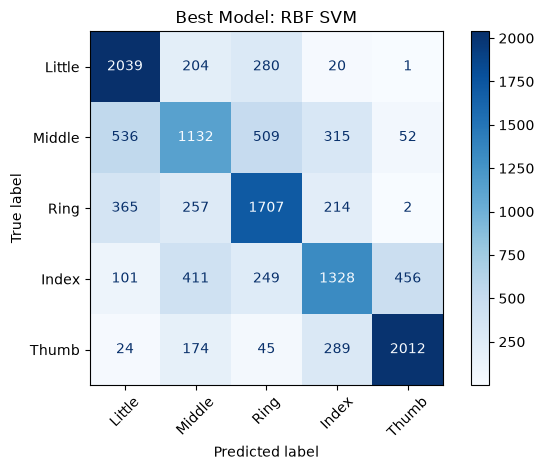

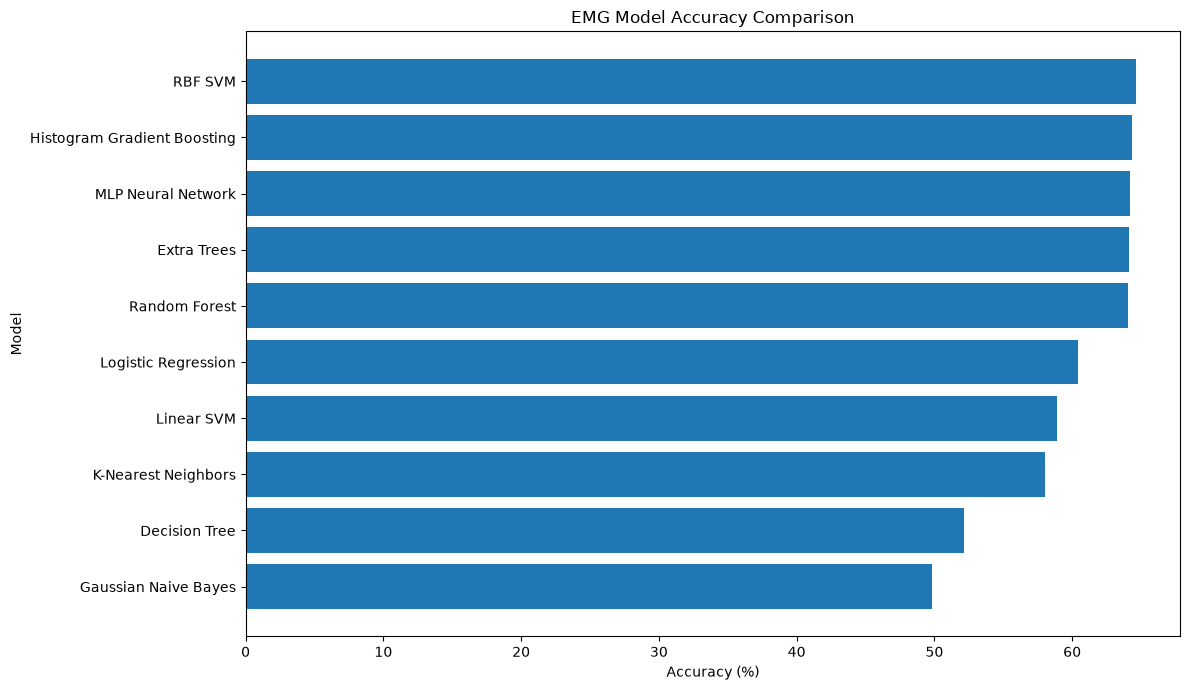

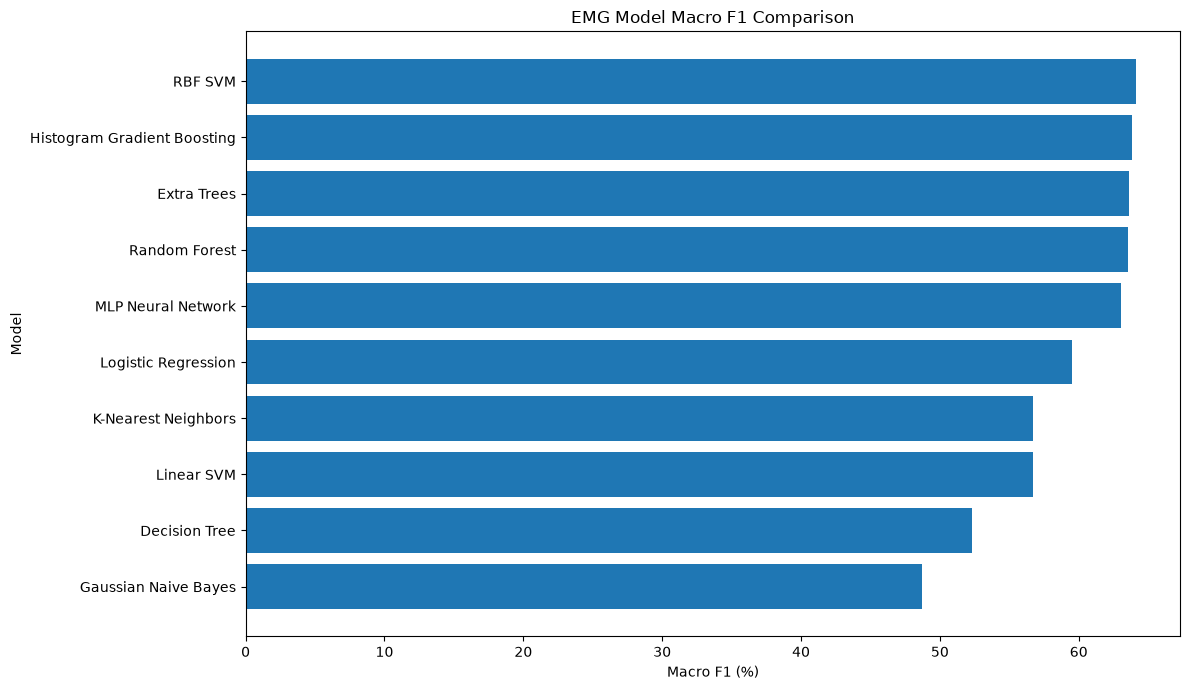

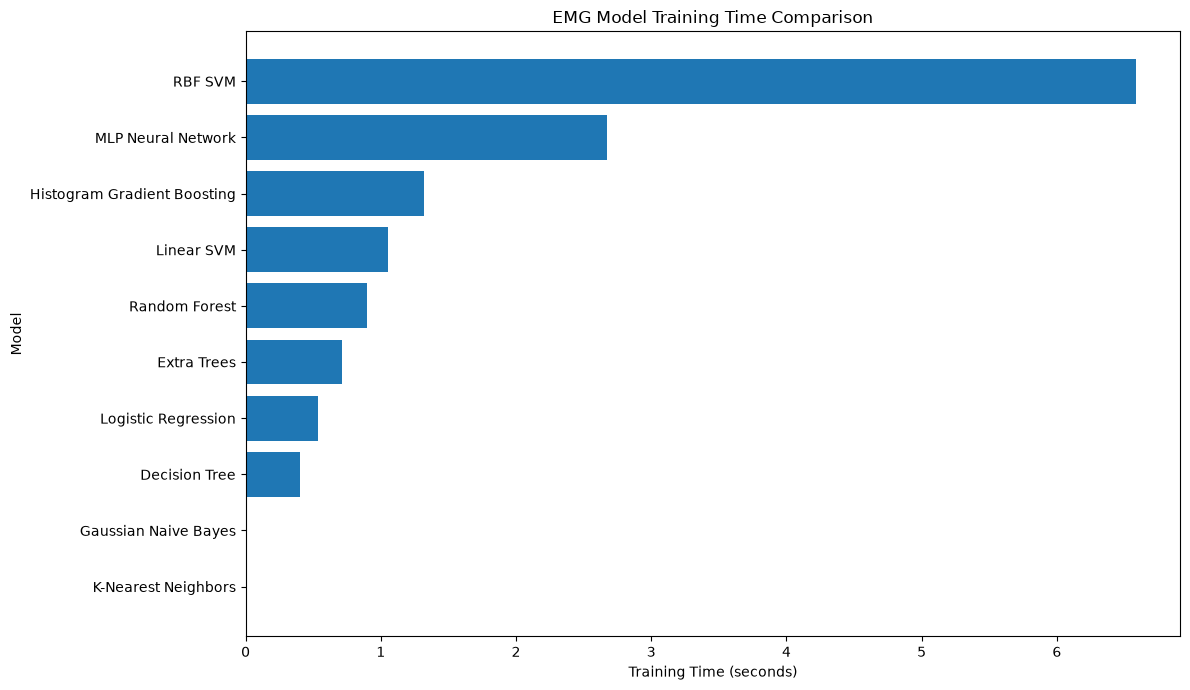



RANDOM BATCH - ALL MODEL PREDICTIONS
Actual finger: Ring
Original session: 10min
                      Model Prediction  Correct
        Logistic Regression     Little    False
        K-Nearest Neighbors     Little    False
                    RBF SVM     Little    False
                 Linear SVM     Little    False
              Decision Tree       Ring     True
              Random Forest     Little    False
                Extra Trees     Little    False
Histogram Gradient Boosting     Little    False
       Gaussian Naive Bayes     Little    False
         MLP Neural Network     Little    False


BEST MODEL RANDOM BATCH PREDICTION
Model: RBF SVM
Actual: Ring
Predicted: Little
Result: INCORRECT


RANDOM FOREST TOP 20 FEATURES
                 Feature  Importance
             EMG1_Median    0.078102
               EMG1_Mean    0.074612
EMG1_Mean_Absolute_Value    0.070228
                EMG1_RMS    0.048865
 EMG1_Standard_Deviation    0.040673
    EMG1_Waveform_Length    0.0405

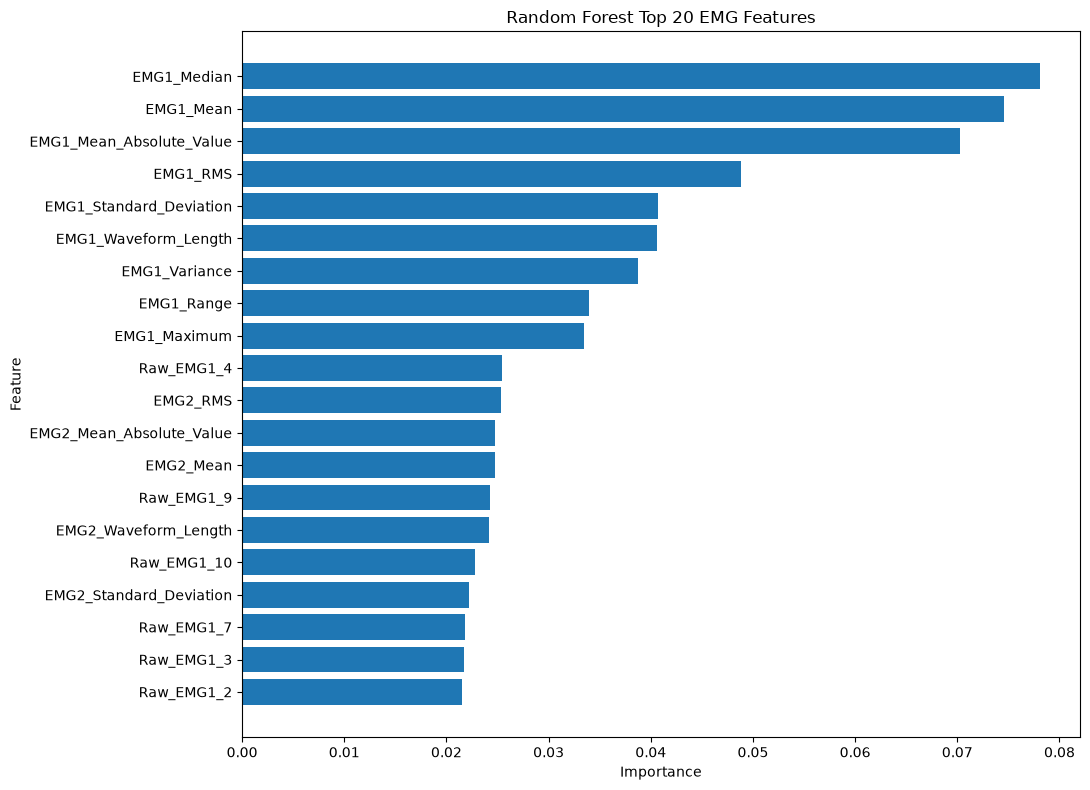



FINAL SUMMARY
Total batches: 31805
Training batches: 19083
Testing batches: 12722
Features per batch: 40
Best model: RBF SVM
Best accuracy: 64.5968%
Best Macro F1: 64.0875%

Results saved to:
10_model_emg_comparison.csv
random_forest_feature_importance.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)


# ============================================================
# LOAD 10-MINUTE DATA
# ============================================================

little_10min = pd.read_csv(
    "../EMG Recordings/little_finger 10mins.csv"
)

middle_10min = pd.read_csv(
    "../EMG Recordings/middle_finger_10mins.csv"
)

ring_10min = pd.read_csv(
    "../EMG Recordings/ring_finger_10mins.csv"
)

index_10min = pd.read_csv(
    "../EMG Recordings/index_finger_10mins.csv"
)

thumb_10min = pd.read_csv(
    "../EMG Recordings/thumb_finger_10mins.csv"
)


# ============================================================
# LOAD 5-MINUTE DATA
# ============================================================

index_5min = pd.read_csv(
    "../EMG Recordings/index emg_2sensor_20260922_124922.csv"
)

middle_5min = pd.read_csv(
    "../EMG Recordings/middle finger emg_2sensor_20260922_124337.csv"
)

ring_5min = pd.read_csv(
    "../EMG Recordings/Ring finger emg_2sensor_20260922_123712.csv"
)

little_5min = pd.read_csv(
    "../EMG Recordings/little finger emg_2sensor_20260922_123054.csv"
)

thumb_5min = pd.read_csv(
    "../EMG Recordings/Thumb finger emg_2sensor_20260922_125701.csv"
)


recordings_10min = {
    "Little": little_10min.head(60745),
    "Middle": middle_10min.head(60745),
    "Ring": ring_10min.head(60745),
    "Index": index_10min.head(60745),
    "Thumb": thumb_10min.head(60745)
}


recordings_5min = {
    "Little": little_5min.head(2870),
    "Middle": middle_5min.head(2870),
    "Ring": ring_5min.head(2870),
    "Index": index_5min.head(2870),
    "Thumb": thumb_5min.head(2870)
}


print("\nLoaded Recordings\n")

for finger in recordings_10min:

    print(
        finger,
        "10 min:",
        recordings_10min[finger].shape,
        "| 5 min:",
        recordings_5min[finger].shape
    )


# ============================================================
# STATISTICAL FEATURES
# ============================================================

def calculate_statistics(values):

    values = values.astype(float)

    mean_value = np.mean(values)
    median_value = np.median(values)
    minimum_value = np.min(values)
    maximum_value = np.max(values)
    standard_deviation = np.std(values)
    variance_value = np.var(values)
    value_range = maximum_value - minimum_value
    rms_value = np.sqrt(np.mean(values ** 2))
    mean_absolute_value = np.mean(np.abs(values))
    waveform_length = np.sum(np.abs(np.diff(values)))

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]


# ============================================================
# CREATE BATCHES
# ============================================================

def create_batches(data, batch_size=10):

    signals = data[
        ["emg1", "emg2"]
    ].values

    batches = []

    for i in range(
        0,
        len(signals),
        batch_size
    ):

        batch = signals[
            i:i + batch_size
        ]

        if len(batch) != batch_size:
            continue

        raw_features = batch.flatten()

        emg1_statistics = calculate_statistics(
            batch[:, 0]
        )

        emg2_statistics = calculate_statistics(
            batch[:, 1]
        )

        combined_features = np.concatenate(
            [
                raw_features,
                emg1_statistics,
                emg2_statistics
            ]
        )

        batches.append(
            combined_features
        )

    return np.array(
        batches
    )


# ============================================================
# FEATURE NAMES
# ============================================================

statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]


feature_names = []


for reading in range(1, 11):

    feature_names.append(
        f"Raw_EMG1_{reading}"
    )

    feature_names.append(
        f"Raw_EMG2_{reading}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


# ============================================================
# COMBINE 10-MINUTE + 5-MINUTE DATA
# ============================================================

emg_features = []

finger_labels = []

session_labels = []


for finger in recordings_10min:

    batches_10min = create_batches(
        recordings_10min[finger]
    )

    batches_5min = create_batches(
        recordings_5min[finger]
    )

    print(
        f"\n{finger}"
    )

    print(
        "10-minute batches:",
        len(batches_10min)
    )

    print(
        "5-minute batches:",
        len(batches_5min)
    )

    combined_batches = np.concatenate(
        [
            batches_10min,
            batches_5min
        ],
        axis=0
    )

    for batch in combined_batches:

        emg_features.append(
            batch
        )

        finger_labels.append(
            finger
        )

    for _ in batches_10min:

        session_labels.append(
            "10min"
        )

    for _ in batches_5min:

        session_labels.append(
            "5min"
        )


emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)


# ============================================================
# DATASET INFORMATION
# ============================================================

print("\n")
print("=" * 70)
print("COMBINED DATASET")
print("=" * 70)


print(
    "Features:",
    emg_features.shape
)


print(
    "Labels:",
    finger_labels.shape
)


print(
    "Features per batch:",
    emg_features.shape[1]
)


print("\nFinger Distribution")

print(
    pd.Series(
        finger_labels
    ).value_counts()
)


print("\nSession Distribution")

print(
    pd.Series(
        session_labels
    ).value_counts()
)


# ============================================================
# RANDOM 60/40 SPLIT
# ============================================================

(
    train_features,
    test_features,
    train_labels,
    test_labels,
    train_sessions,
    test_sessions

) = train_test_split(

    emg_features,
    finger_labels,
    session_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    shuffle=True,

    stratify=finger_labels
)


print("\n")
print("=" * 70)
print("RANDOM TRAIN / TEST SPLIT")
print("=" * 70)


print(
    "Training:",
    train_features.shape
)


print(
    "Testing:",
    test_features.shape
)


print("\nTraining Session Distribution")

print(
    pd.Series(
        train_sessions
    ).value_counts()
)


print("\nTesting Session Distribution")

print(
    pd.Series(
        test_sessions
    ).value_counts()
)


# ============================================================
# STANDARD SCALING
# ============================================================

scaler = StandardScaler()


train_features_scaled = scaler.fit_transform(
    train_features
)


test_features_scaled = scaler.transform(
    test_features
)


# ============================================================
# RANDOM TEST BATCH
# ============================================================

random_index = np.random.randint(
    0,
    len(test_features)
)


random_raw_features = test_features[
    random_index
]


random_scaled_features = test_features_scaled[
    random_index
]


random_label = test_labels[
    random_index
]


random_session = test_sessions[
    random_index
]


raw_signal = random_raw_features[
    :20
].reshape(
    10,
    2
)


print("\n")
print("=" * 70)
print("RANDOM TEST BATCH")
print("=" * 70)


print(
    "Finger:",
    random_label
)


print(
    "Original session:",
    random_session
)


print(
    "Test index:",
    random_index
)


print("\nReading | EMG1 | EMG2")


for i in range(10):

    print(
        f"{i + 1:>7} | "
        f"{raw_signal[i, 0]:>8.2f} | "
        f"{raw_signal[i, 1]:>8.2f}"
    )


# ============================================================
# RANDOM BATCH STATISTICS
# ============================================================

emg1_stats = random_raw_features[
    20:30
]


emg2_stats = random_raw_features[
    30:40
]


print("\nStatistical Features")


print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{emg1_stats[i]:>15.4f}"
        f"{emg2_stats[i]:>15.4f}"
    )


# ============================================================
# 10 MACHINE LEARNING MODELS
# ============================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=42
        ),

    "K-Nearest Neighbors":
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            n_jobs=-1
        ),

    "RBF SVM":
        SVC(
            kernel="rbf",
            C=3.0,
            gamma="scale"
        ),

    "Linear SVM":
        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42,
            min_samples_leaf=2
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.08,
            max_leaf_nodes=31,
            random_state=42
        ),

    "Gaussian Naive Bayes":
        GaussianNB(),

    "MLP Neural Network":
        MLPClassifier(
            hidden_layer_sizes=(
                128,
                64
            ),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            validation_fraction=0.10,
            n_iter_no_change=15,
            random_state=42
        )
}


# ============================================================
# TRAIN AND TEST ALL MODELS
# ============================================================

results = []

trained_models = {}

model_predictions = {}


print("\n")
print("=" * 70)
print("TRAINING 10 MACHINE LEARNING MODELS")
print("=" * 70)


for model_number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{model_number}/10] {model_name}"
    )

    try:

        training_start = time.perf_counter()

        model.fit(
            train_features_scaled,
            train_labels
        )

        training_end = time.perf_counter()


        prediction_start = time.perf_counter()

        predicted_labels = model.predict(
            test_features_scaled
        )

        prediction_end = time.perf_counter()


        accuracy = accuracy_score(
            test_labels,
            predicted_labels
        )


        balanced_accuracy = balanced_accuracy_score(
            test_labels,
            predicted_labels
        )


        precision = precision_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        recall = recall_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        macro_f1 = f1_score(
            test_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )


        weighted_f1 = f1_score(
            test_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )


        training_time = (
            training_end -
            training_start
        )


        prediction_time = (
            prediction_end -
            prediction_start
        )


        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time
            }
        )


        trained_models[
            model_name
        ] = model


        model_predictions[
            model_name
        ] = predicted_labels


        print(
            f"Accuracy: "
            f"{accuracy * 100:.4f}%"
        )


        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.4f}%"
        )


        print(
            f"Training time: "
            f"{training_time:.3f} seconds"
        )


        print(
            f"Prediction time: "
            f"{prediction_time:.3f} seconds"
        )


    except Exception as error:

        print(
            "FAILED:",
            error
        )


# ============================================================
# RESULTS TABLE
# ============================================================

results = pd.DataFrame(
    results
)


results = results.sort_values(
    by=[
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)


results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(results) + 1
    )
)


display_results = results.copy()


percentage_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]


for column in percentage_columns:

    display_results[
        column
    ] = (
        display_results[column] * 100
    )


print("\n")
print("=" * 120)
print("FINAL MODEL COMPARISON")
print("=" * 120)


print(
    display_results.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "10_model_emg_comparison.csv",
    index=False
)


# ============================================================
# BEST MODEL
# ============================================================

best_model_name = results.iloc[
    0
]["Model"]


best_model = trained_models[
    best_model_name
]


best_predictions = model_predictions[
    best_model_name
]


best_accuracy = results.iloc[
    0
]["Accuracy"]


best_macro_f1 = results.iloc[
    0
]["Macro F1"]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)


print(
    "Model:",
    best_model_name
)


print(
    f"Accuracy: "
    f"{best_accuracy * 100:.4f}%"
)


print(
    f"Macro F1: "
    f"{best_macro_f1 * 100:.4f}%"
)


# ============================================================
# BEST MODEL CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report\n")


print(
    classification_report(
        test_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# BEST MODEL CONFUSION MATRIX
# ============================================================

finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_predictions,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"Best Model: {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()


# ============================================================
# ACCURACY COMPARISON
# ============================================================

accuracy_plot = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    accuracy_plot["Model"],
    accuracy_plot["Accuracy"] * 100
)


plt.xlabel(
    "Accuracy (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "EMG Model Accuracy Comparison"
)


plt.tight_layout()


plt.show()


# ============================================================
# MACRO F1 COMPARISON
# ============================================================

f1_plot = results.sort_values(
    "Macro F1",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    f1_plot["Model"],
    f1_plot["Macro F1"] * 100
)


plt.xlabel(
    "Macro F1 (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "EMG Model Macro F1 Comparison"
)


plt.tight_layout()


plt.show()


# ============================================================
# TRAINING TIME COMPARISON
# ============================================================

time_plot = results.sort_values(
    "Training Time",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    time_plot["Model"],
    time_plot["Training Time"]
)


plt.xlabel(
    "Training Time (seconds)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "EMG Model Training Time Comparison"
)


plt.tight_layout()


plt.show()


# ============================================================
# RANDOM BATCH PREDICTION WITH EVERY MODEL
# ============================================================

print("\n")
print("=" * 70)
print("RANDOM BATCH - ALL MODEL PREDICTIONS")
print("=" * 70)


print(
    "Actual finger:",
    random_label
)


print(
    "Original session:",
    random_session
)


random_prediction_results = []


for model_name, model in trained_models.items():

    prediction = model.predict(
        random_scaled_features.reshape(
            1,
            -1
        )
    )[0]


    correct = (
        prediction ==
        random_label
    )


    random_prediction_results.append(
        {
            "Model":
                model_name,

            "Prediction":
                prediction,

            "Correct":
                correct
        }
    )


random_prediction_results = pd.DataFrame(
    random_prediction_results
)


print(
    random_prediction_results.to_string(
        index=False
    )
)


# ============================================================
# RANDOM BATCH BEST MODEL
# ============================================================

best_random_prediction = best_model.predict(
    random_scaled_features.reshape(
        1,
        -1
    )
)[0]


print("\n")
print("=" * 70)
print("BEST MODEL RANDOM BATCH PREDICTION")
print("=" * 70)


print(
    "Model:",
    best_model_name
)


print(
    "Actual:",
    random_label
)


print(
    "Predicted:",
    best_random_prediction
)


if best_random_prediction == random_label:

    print(
        "Result: CORRECT"
    )

else:

    print(
        "Result: INCORRECT"
    )


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

random_forest_model = trained_models.get(
    "Random Forest"
)


if random_forest_model is not None:

    feature_importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest_model.feature_importances_
        }
    )


    feature_importance = feature_importance.sort_values(
        "Importance",
        ascending=False
    ).reset_index(
        drop=True
    )


    print("\n")
    print("=" * 70)
    print("RANDOM FOREST TOP 20 FEATURES")
    print("=" * 70)


    print(
        feature_importance.head(
            20
        ).to_string(
            index=False
        )
    )


    feature_importance.to_csv(
        "random_forest_feature_importance.csv",
        index=False
    )


    top_features = feature_importance.head(
        20
    ).sort_values(
        "Importance",
        ascending=True
    )


    plt.figure(
        figsize=(11, 8)
    )


    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )


    plt.xlabel(
        "Importance"
    )


    plt.ylabel(
        "Feature"
    )


    plt.title(
        "Random Forest Top 20 EMG Features"
    )


    plt.tight_layout()


    plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)


print(
    "Total batches:",
    len(emg_features)
)


print(
    "Training batches:",
    len(train_features)
)


print(
    "Testing batches:",
    len(test_features)
)


print(
    "Features per batch:",
    emg_features.shape[1]
)


print(
    "Best model:",
    best_model_name
)


print(
    f"Best accuracy: "
    f"{best_accuracy * 100:.4f}%"
)


print(
    f"Best Macro F1: "
    f"{best_macro_f1 * 100:.4f}%"
)


print(
    "\nResults saved to:"
)


print(
    "10_model_emg_comparison.csv"
)


print(
    "random_forest_feature_importance.csv"
)